<a href="https://colab.research.google.com/github/hariszidan-ui/ProjectARKA/blob/haris/haris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Dari Sistem Persamaan Linear ke Dimensi Tersembunyi

Catatan dari pembuat:

Notebook ini terdiri atas dua bagian. Bagian A merupakan soal pemanasan berbentuk **fill in the blanks** untuk memperkenalkan hubungan antara regresi linear dan Sistem Persamaan Linear (SPL) yang telah dipelajari di kelas. Bagian B merupakan task supervised learning. Silakan dieksplorasi!

## Tujuan Pembelajaran

Anda akan menggunakan rank, null space, least squares, reduksi dimensi, perubahan basis, dan feature mapping dalam satu alur supervised learning. Pastikan kode dapat dijalankan ulang dan setiap keputusan didukung oleh hasil eksperimen.

## Setup dan Import

In [206]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

np.set_printoptions(suppress=True, precision=6)
RANDOM_STATE = 42

In [207]:
import os, sys
import subprocess
import importlib

import seaborn as sns

REPO_ROOT = Path("/content/repo")

def git_pull():
    subprocess.run(["git", "-C", str(REPO_ROOT), "pull", "-q"], check=True)

if not (REPO_ROOT / ".git").exists():
    if REPO_ROOT.exists():
        import shutil
        shutil.rmtree(REPO_ROOT)
    REPO_ROOT.mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["git", "clone", "-b", "haris",
         "https://github.com/hariszidan-ui/ProjectARKA", str(REPO_ROOT)],
        check=True,
    )
    git_pull()
else: git_pull()

sys.path.append(str(REPO_ROOT / "src"))

import haris
importlib.reload(haris)

<module 'haris' from '/content/repo/src/haris.py'>

## Fungsi Evaluasi

Gunakan fungsi berikut untuk menghitung RMSE pada data validasi dengan definisi yang sama seperti leaderboard Kaggle. Nilai yang lebih rendah menunjukkan prediksi yang lebih baik, sedangkan prediksi sempurna memperoleh nilai 0. Target untuk `test.csv` tidak tersedia.

In [208]:
def rmse(y_true, y_pred):
    """Menghitung Root Mean Squared Error (RMSE)."""
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true dan y_pred harus memiliki bentuk yang sama.")
    if y_true.size == 0:
        raise ValueError("Data harus memiliki sekurang-kurangnya satu observasi.")
    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError("Target dan prediksi hanya boleh memuat nilai hingga.")

    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


Anda juga dapat menggunakan fungsi `root_mean_squared_error` bawaan scikit-learn:

```python
error = root_mean_squared_error(y_true, y_pred)
```

# Bagian A: Tutorial SPL dengan Linear Regression

Bagian ini menggunakan tiga dataset untuk mempelajari SPL dengan solusi unik, tak hingga banyak solusi, dan sistem inkonsisten. Setiap baris merepresentasikan satu persamaan, setiap kolom fitur merepresentasikan satu variabel, dan kolom target menjadi ruas kanan $y$.

Gunakan `LinearRegression(fit_intercept=False)` karena SPL sudah berbentuk $X\beta=y$. Menambahkan intercept berarti menambahkan variabel baru ke sistem.

## A0. Memuat Dataset SPL

In [209]:
import kagglehub, shutil

KAGGLE_INPUT_ROOT = Path(kagglehub.competition_download('project-a-r-k-a-hidden-dimensions')).parent
print(KAGGLE_INPUT_ROOT)

/root/.cache/kagglehub/competitions


In [210]:
REQUIRED_FILES = {
    'train.csv',
    'test.csv',
    'calibration.csv',
    'sample_submission.csv',
    'spl_01_harga_rumah.csv',
    'spl_02_pendapatan_supermarket.csv',
    'spl_03_risiko_fraud.csv',
}

DATA_DIR = next(
    (
        path for path in KAGGLE_INPUT_ROOT.iterdir()
        if path.is_dir()
        and REQUIRED_FILES.issubset({file.name for file in path.iterdir()})
    ),
    None,
)

if DATA_DIR is None:
    raise FileNotFoundError(
        'Dataset kompetisi tidak ditemukan di /kaggle/input. '
        'Tambahkan dataset kompetisi ke notebook, lalu jalankan kembali sel ini.'
    )


In [211]:
def dataframe_to_system(dataframe, target_column):
    feature_columns = [
        column for column in dataframe.columns
        if column != target_column
    ]
    X = dataframe[feature_columns].to_numpy(dtype=float)
    y = dataframe[target_column].to_numpy(dtype=float)
    return X, y, feature_columns


unique_df = pd.read_csv(DATA_DIR / 'spl_01_harga_rumah.csv')
infinite_df = pd.read_csv(DATA_DIR / 'spl_02_pendapatan_supermarket.csv')
inconsistent_df = pd.read_csv(DATA_DIR / 'spl_03_risiko_fraud.csv')

X_unique, y_unique, unique_features = dataframe_to_system(
    unique_df,
    'price_usd_thousand',
)
X_infinite, y_infinite, infinite_features = dataframe_to_system(
    infinite_df,
    'daily_revenue_usd',
)
X_inconsistent, y_inconsistent, inconsistent_features = dataframe_to_system(
    inconsistent_df,
    'fraud_risk_score',
)

for name, X, feature_names in [
    ('Solusi unik', X_unique, unique_features),
    ('Tak hingga banyak solusi', X_infinite, infinite_features),
    ('Inkonsisten', X_inconsistent, inconsistent_features),
]:
    print(f'{name}: {X.shape[0]} persamaan, {X.shape[1]} variabel')

display(unique_df.head(3))
display(infinite_df.head(3))
display(inconsistent_df.head(3))


Solusi unik: 20 persamaan, 20 variabel
Tak hingga banyak solusi: 45 persamaan, 50 variabel
Inkonsisten: 21 persamaan, 20 variabel


,land_area_sqm,building_area_sqm,bedrooms,bathrooms,floors,house_age_years,distance_to_city_center_km,distance_to_school_km,garage_slots,parks_within_1km,...,street_width_m,flood_risk_level,crime_incidents_per_1000_residents,air_quality_index,fiber_internet_speed_mbps,solar_panel_capacity_kw,ceiling_height_m,water_supply_hours_per_day,daily_sunlight_hours,price_usd_thousand
0,368,100,2,1,1,5,8.3,0.3,1,3,...,9,2,2,65,108,1.6,2.6,23,10,603.45
1,331,104,4,3,1,21,3.9,3.2,3,3,...,7,5,9,94,150,2.6,3.6,15,9,534.70
2,318,89,1,2,2,33,14.3,4.8,3,1,...,10,1,25,88,73,3.3,2.7,15,10,441.65


,milk_liters,eggs_dozens,bread_loaves,rice_kg,cooking_oil_liters,sugar_kg,flour_kg,total_dry_goods_kg,instant_noodle_packs,canned_tuna_cans,...,shampoo_bottles,soap_bars,toothpaste_tubes,toilet_paper_packs,laundry_detergent_bottles,dishwashing_liquid_bottles,paper_towel_rolls,diaper_packs,baby_formula_cans,daily_revenue_usd
0,25,62,63,26,10,73,2,101,2,22,...,3,8,16,18,28,20,11,19,3,3811.0
1,55,21,62,47,1,38,11,96,67,44,...,18,39,10,34,24,26,11,5,13,3494.6
2,58,7,67,58,51,50,57,165,15,2,...,5,19,39,10,26,25,38,2,4,3731.3


,transaction_amount_usd,hours_since_last_transaction,transactions_last_24h,transactions_prev_6d,distance_from_home_km,distance_from_last_transaction_km,account_age_months,card_age_months,is_international_ip,failed_login_attempts_24h,...,new_devices_30d,foreign_transactions_30d,declined_transactions_30d,merchant_risk_level,merchant_age_years,online_purchase_ratio_pct,night_transactions_30d,credit_utilization_pct,chargebacks_12m,fraud_risk_score
0,101,48,15,2,29,24,32,26,1,4,...,1,19,5,6,22,27,20,47,3,50.96
1,134,37,18,1,90,9,107,34,0,8,...,7,1,9,6,12,24,15,90,3,59.89
2,199,28,8,16,12,39,103,20,0,1,...,6,7,1,3,4,78,2,53,6,43.81


## A1. Solusi Unik

Dataset harga rumah memiliki satu persamaan untuk setiap observasi dan satu variabel untuk setiap fitur. Lengkapi kode berikut, lalu bandingkan rank $X$ dengan rank augmented matrix $[X\mid y]$.

In [212]:
model_unique = LinearRegression(fit_intercept=False)
model_unique.fit(X_unique, y_unique)

beta_unique = model_unique.coef_
prediction_unique = model_unique.predict(X_unique)

rank_X_unique = np.linalg.matrix_rank(X_unique)
augmented_unique = np.column_stack([X_unique, y_unique])
rank_augmented_unique = np.linalg.matrix_rank(augmented_unique)
residual_unique = np.linalg.norm(y_unique - prediction_unique)

print('beta:', beta_unique)
print('rank X:', rank_X_unique)
print('rank augmented:', rank_augmented_unique)
print('residual norm:', residual_unique)


beta: [  0.8    1.5    6.     8.    10.    -1.2   -2.5   -2.     7.     4.
  -1.5    3.   -12.    -2.5   -0.4    0.15   6.    20.     2.     5.  ]
rank X: 20
rank augmented: 20
residual norm: 2.2147059711162635e-12


**Pertanyaan:** Mengapa residual nol dan rank yang sama dengan jumlah variabel menunjukkan solusi unik?

## A2. Tak Hingga Banyak Solusi

Dataset pendapatan supermarket memiliki lebih banyak variabel daripada persamaan independen. `LinearRegression` menghasilkan salah satu solusi. Temukan vektor null space untuk membentuk solusi lain.

In [213]:
model_infinite = LinearRegression(fit_intercept=False)
model_infinite.fit(X_infinite, y_infinite)
beta_infinite = model_infinite.coef_

_, singular_values, Vt = np.linalg.svd(X_infinite, full_matrices=True)
null_vector = Vt[-1]
beta_alternative = beta_infinite + 5 * null_vector

rank_X_infinite = np.linalg.matrix_rank(X_infinite)
rank_augmented_infinite = np.linalg.matrix_rank(
    np.column_stack([X_infinite, y_infinite])
)

print('beta from model:', beta_infinite)
print('null-space check:', np.linalg.norm(X_infinite @ null_vector))
print('first residual:', np.linalg.norm(X_infinite @ beta_infinite - y_infinite))
print('alternative residual:', np.linalg.norm(X_infinite @ beta_alternative - y_infinite))
print('ranks:', rank_X_infinite, rank_augmented_infinite)


beta from model: [ 1.8    3.2    2.5    0.775  3.6    0.275  0.075  1.125  0.6    1.7
  3.9    4.8    0.9   -0.35   5.65   1.55   6.85   1.2   -0.3    1.
  1.9    0.94   0.14  -0.06   0.34   1.36   1.4    5.2    4.6    4.1
  7.3    3.4    1.2    2.7    2.4    1.9    0.5   -0.2    0.8    0.2
  1.3    4.4    0.8    2.6    6.9    8.7    2.8    2.2   11.9   14.5  ]
null-space check: 1.8612086195890345e-13
first residual: 1.4551915228366852e-11
alternative residual: 1.4214037590216125e-11
ranks: 45 45


**Pertanyaan:** Mengapa dua koefisien berbeda dapat menghasilkan prediksi yang sama?

## A3. Sistem Inkonsisten

Pada sistem inkonsisten, regresi menghasilkan solusi least squares, bukan solusi eksak SPL. Lengkapi kode berikut untuk membandingkan rank matriks fitur, rank augmented matrix, dan residual model.

In [214]:
model_inconsistent = LinearRegression(fit_intercept=False)
model_inconsistent.fit(X_inconsistent, y_inconsistent)

beta_inconsistent = model_inconsistent.coef_
prediction_inconsistent = model_inconsistent.predict(X_inconsistent)
residual_vector = y_inconsistent - prediction_inconsistent

rank_X_inconsistent = np.linalg.matrix_rank(X_inconsistent)
rank_augmented_inconsistent = np.linalg.matrix_rank(
    np.column_stack([X_inconsistent, y_inconsistent])
)
normal_equation_check = X_inconsistent.T @ residual_vector

print('beta least squares:', beta_inconsistent)
print('residual norm:', np.linalg.norm(residual_vector))
print('ranks:', rank_X_inconsistent, rank_augmented_inconsistent)
print('X^T residual:', normal_equation_check)


beta least squares: [ 0.053784 -0.012632  0.897589  0.094257  0.147488  0.079151 -0.062707
 -0.070489  4.402374  1.016649  0.897852  0.872079  0.272681  0.268581
  1.851717 -0.276896  0.041358  0.003702 -0.021697  2.137705]
residual norm: 3.625
ranks: 20 21
X^T residual: [-0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0.
 -0. -0.]


**Pertanyaan:** Mengapa koefisien tetap tersedia ketika $X\beta=y$ tidak mempunyai solusi eksak?

# Bagian B: Project A.R.K.A.,

A.R.K.A. adalah rover pencarian dan penyelamatan. **ATLAS**, **BOREALIS**, dan **CYGNUS** merupakan tiga profil firmware sensor. `train.csv` memuat misi berlabel yang direkam menggunakan ATLAS, sedangkan `test.csv` memuat misi tanpa label yang direkam menggunakan BOREALIS dan CYGNUS. Setiap profil merepresentasikan keadaan fisik rover melalui koordinat sensor yang berbeda.

`calibration.csv` memuat pengukuran misi kalibrasi yang sama di bawah ketiga profil. Baris dengan `calibration_id` yang sama merepresentasikan keadaan fisik rover yang sama. File ini tidak memiliki kolom `energy_consumption`, tetapi dapat digunakan untuk mempelajari hubungan antarrepresentasi sensor.

Prediksi dinilai menggunakan Root Mean Squared Error (RMSE). Nilai yang lebih rendah menunjukkan prediksi yang lebih baik, sedangkan prediksi sempurna memperoleh nilai 0.

## B1. Memuat Data

In [215]:
train_df = pd.read_csv(DATA_DIR / 'train.csv')

test_df = pd.read_csv(DATA_DIR / 'test.csv')
calibration_df = pd.read_csv(DATA_DIR / 'calibration.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

TARGET = 'energy_consumption'
ID_COLUMN = 'id'
FIRMWARE_COLUMN = 'firmware'
SENSOR_COLUMNS = [column for column in train_df if column.startswith('sensor_')]

print('Train:', train_df.shape)
print('Test:', test_df.shape)
print('Calibration:', calibration_df.shape)
display(train_df.head())
display(calibration_df.head())


Train: (1500, 51)
Test: (900, 50)
Calibration: (288, 50)


,id,firmware,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_40,sensor_41,sensor_42,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,energy_consumption
0,ARKA-TR-01339,ATLAS,41,-32,-45,1,-8,31,-16,10,...,-38,-54,12,5,-6,-20,-14,16,23,4894
1,ARKA-TR-01391,ATLAS,25,-38,-23,1,-40,13,-20,10,...,-57,-6,2,-35,-54,42,-30,8,-25,3282
2,ARKA-TR-00871,ATLAS,22,-47,-18,-6,-39,0,-26,3,...,-37,2,4,-43,-62,52,-38,16,-33,4632
3,ARKA-TR-00634,ATLAS,27,-35,-26,3,-38,18,-18,12,...,-12,-25,11,-21,-35,17,-31,24,-6,5365
4,ARKA-TR-00159,ATLAS,35,-23,-38,11,-30,38,-10,20,...,-40,-38,5,-7,-22,1,-14,4,7,4483


,calibration_id,firmware,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_39,sensor_40,sensor_41,sensor_42,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48
0,CAL-0013,ATLAS,26,-50,-23,-10,-27,-1,-28,-1,...,-11,-46,-23,17,-25,-37,19,-41,40,-8
1,CAL-0092,BOREALIS,61,-22,26,-24,64,-5,-10,-36,...,-26,49,-39,41,22,2,10,20,-26,72
2,CAL-0076,ATLAS,20,-59,-14,-16,-33,-16,-34,-7,...,-12,-54,-8,18,-39,-52,38,-52,48,-23
3,CAL-0054,CYGNUS,20,37,20,8,8,-40,-19,20,...,41,43,6,17,-9,35,-1,-3,-48,-39
4,CAL-0085,BOREALIS,46,-12,36,-44,59,15,-15,-11,...,-50,16,-27,17,34,20,16,32,4,54


## B2. Exploratory Data Analysis

Periksa kualitas data, distribusi target, perbedaan profil firmware, pasangan `calibration_id`, serta struktur matriks sensor. Gunakan ringkasan numerik dan visualisasi yang sesuai. Jelaskan keterkaitan setiap temuan dengan model yang akan dibangun.

In [216]:
# TODO: eksplorasi data.
display(train_df.describe())
print(train_df[FIRMWARE_COLUMN].value_counts())
print(test_df[FIRMWARE_COLUMN].value_counts())
print(calibration_df.groupby('calibration_id')[FIRMWARE_COLUMN].nunique().describe())


,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,sensor_09,sensor_10,...,sensor_40,sensor_41,sensor_42,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,energy_consumption
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,...,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,25.120667,-38.500000,-23.105333,0.515333,-39.274000,12.469333,-20.333333,9.515333,-13.896667,-39.192000,...,-19.161333,-24.020667,14.070000,-23.006667,-35.979333,17.967333,-36.088667,32.170667,-6.979333,5050.405333
std,8.486742,15.404681,11.964517,13.082451,20.227993,21.294836,10.269787,13.082451,18.717395,8.180694,...,21.832722,18.461585,8.385621,16.558062,18.461585,23.633704,15.483431,21.298544,18.461585,655.339607
min,7.000000,-74.000000,-47.000000,-29.000000,-82.000000,-35.000000,-44.000000,-20.000000,-55.000000,-57.000000,...,-67.000000,-66.000000,-4.000000,-59.000000,-78.000000,-36.000000,-66.000000,-16.000000,-49.000000,2208.000000
25%,18.750000,-50.000000,-33.000000,-9.000000,-55.000000,-4.000000,-28.000000,0.000000,-28.000000,-45.000000,...,-36.000000,-37.000000,8.000000,-35.000000,-49.000000,1.750000,-49.000000,16.000000,-20.000000,4680.250000
50%,25.000000,-38.000000,-23.000000,0.000000,-40.000000,12.000000,-20.000000,9.000000,-15.000000,-39.000000,...,-19.000000,-24.000000,14.000000,-23.000000,-36.000000,18.000000,-37.000000,32.000000,-7.000000,5136.500000
75%,31.000000,-29.000000,-13.000000,10.000000,-23.000000,28.000000,-14.000000,19.000000,-1.000000,-33.000000,...,-2.000000,-11.000000,20.000000,-11.000000,-23.000000,35.000000,-23.000000,48.000000,6.000000,5504.250000
max,43.000000,-2.000000,1.000000,31.000000,2.000000,61.000000,4.000000,40.000000,29.000000,-21.000000,...,29.000000,18.000000,32.000000,13.000000,6.000000,72.000000,-6.000000,80.000000,35.000000,7232.000000


firmware
ATLAS    1500
Name: count, dtype: int64
firmware
CYGNUS      450
BOREALIS    450
Name: count, dtype: int64
count    96.0
mean      3.0
std       0.0
min       3.0
25%       3.0
50%       3.0
75%       3.0
max       3.0
Name: firmware, dtype: float64


In [217]:
df = train_df.copy()
cdf = calibration_df.copy()

<Axes: >

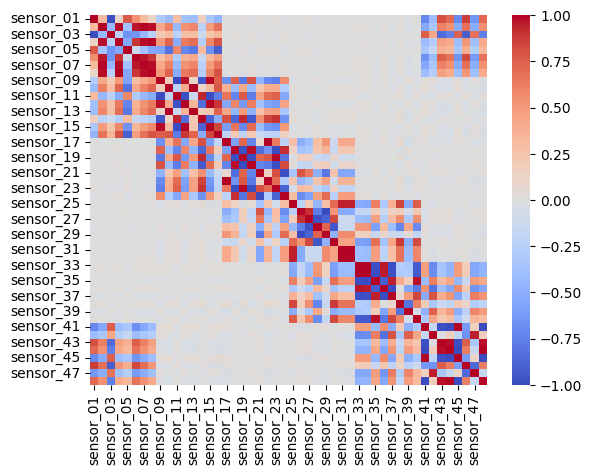

In [218]:
df_corr = df[SENSOR_COLUMNS].corr()
sns.heatmap(df_corr, cmap='coolwarm')

In [230]:
cols_linind = []
for i in range(df[SENSOR_COLUMNS].shape[1]):
    if np.linalg.matrix_rank(df[SENSOR_COLUMNS].iloc[:, [i] + cols_linind].to_numpy()) > len(cols_linind):
        cols_linind.append(i)

INDEPENDENT_SENSORS = [SENSOR_COLUMNS[i] for i in cols_linind]

len(INDEPENDENT_SENSORS)

7

### Analisis EDA

Tuliskan temuan dan hipotesis mengenai hubungan antara data training, data test, dan data kalibrasi.

## B3. Baseline Supervised Learning

Baseline berikut menggunakan regresi linear pada validation split dari data ATLAS. Gunakan hasilnya sebagai titik awal untuk mengevaluasi pendekatan berikutnya. Skor validasi pada ATLAS belum menunjukkan kinerja model pada BOREALIS dan CYGNUS.

In [220]:
X = train_df[SENSOR_COLUMNS]
y = train_df[TARGET]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

baseline = LinearRegression()
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_valid)

print('RMSE:', mean_squared_error(y_valid, baseline_prediction) ** 0.5)
print('R²:', r2_score(y_valid, baseline_prediction))
print('Competition RMSE:', rmse(y_valid, baseline_prediction))


RMSE: 499.9048212160718
R²: 0.5011675714544772
Competition RMSE: 499.9048212160718


## B3.1 Submission Valid Pertama

Prediktor rata-rata target menghasilkan submission valid untuk memeriksa format dan alur penyimpanan CSV. Gunakan skor leaderboard-nya sebagai baseline awal.

In [231]:
mean_baseline_value = train_df[TARGET].mean()

baseline_submission = sample_submission.copy()
baseline_submission[TARGET] = mean_baseline_value

assert baseline_submission[ID_COLUMN].equals(test_df[ID_COLUMN])
assert baseline_submission[TARGET].notna().all()

baseline_submission.to_csv(
    'baseline_mean_submission.csv',
    index=False,
)

print('Mean prediction:', mean_baseline_value)
display(baseline_submission.head())


Mean prediction: 5050.405333333333


,id,energy_consumption
0,ARKA-TE-00021,5050.405333
1,ARKA-TE-00260,5050.405333
2,ARKA-TE-00269,5050.405333
3,ARKA-TE-00468,5050.405333
4,ARKA-TE-00065,5050.405333


## B4. Feature Engineering dan Eksperimen

Rancang representasi yang dapat digunakan untuk ATLAS, BOREALIS, dan CYGNUS. Gunakan pasangan misi pada `calibration.csv` untuk mengevaluasi hubungan antarprofil. Selanjutnya, lakukan eksperimen dengan pemetaan fitur dan model supervised learning.

Catat representasi, jumlah fitur, RMSE validasi, $R^2$ validasi, dan alasan matematis untuk setiap eksperimen.

In [232]:
experiment_results = pd.DataFrame(columns=[
    'experiment', 'representation', 'n_features', 'rmse', 'r2'
])

# TODO: implementasikan feature engineering dan eksperimen terbaik.
experiment_results


,experiment,representation,n_features,rmse,r2


### Analisis Eksperimen

Jelaskan bagaimana struktur matriks, hubungan antarprofil, dan feature mapping memengaruhi hasil. Bandingkan metode berdasarkan hasil validasi dan alasan matematisnya.

## B5. Model Final dan Submission

In [233]:
# TODO: latih seluruh pipeline pada train_df dan prediksi test_df.
test_prediction = None

# Silakan uncomment setelah test_prediction tersedia.
# submission = sample_submission.copy()
# submission[TARGET] = test_prediction
# assert submission[ID_COLUMN].equals(test_df[ID_COLUMN])
# assert submission[TARGET].notna().all()
# submission.to_csv('submission.csv', index=False)
# display(submission.head())
